# 1. From Separate Modules to One Dividing, Dying Cell

Across Tutorials 3, 4, and 5, we built and ran three separate B-cell signalling models:
1. **NF-κB signalling** (Tutorials 3 & 4) — translating receptor inputs (IKK and NIK) into nuclear transcription factors (`RelA:p50`, `cRel:p50`, `RelB:p52`).
2. **Apoptosis** (Tutorial 5, Chapter 1) — deciding whether and when a cell dies (`Cleaved PARP`), opposed by **BCL2**.
3. **The Cell Cycle** (Tutorial 5, Chapter 2) — deciding how fast a cell progresses through **G1 → S → G2 → M** and divides, accelerated by **c-MYC**.

In a real B-cell — and in aggressive B-cell lymphomas such as **Double-Hit Diffuse Large B-Cell Lymphoma (DLBCL)** — these networks do **not** run in isolation. They operate inside the **same cell**, coupled together so that NF-κB controls both proliferation (`cMyc`, `CycD`) and survival (`Bcl2`), while each cell continuously races between **dividing** into two daughters and **dying** by apoptosis.

In this tutorial, we build the full **agent-based multiscale B-cell model** from *Norris et al.* (**Blood Cancer Journal**, 2024, 14:105, [doi:10.1038/s41408-024-01090-y](https://www.nature.com/articles/s41408-024-01090-y)) step by step:
- **Chapter 1 (this page):** Wire the 5 CSV modules into a single **193-species** ODE model and understand how **callbacks** turn one cell into a dividing, dying lineage.
- **Chapter 2:** Simulate a heterogeneous population of virtual B-cells to recreate **Figure 2B** (**MYC + BCL2** double-hit synergy).
- **Chapter 3:** Compare **MYC + BCL6** against **MYC + BCL2** (**Figure 2C**) to see why *BCL6* behaves differently clinically and mechanistically.

:::{tip} Start your live Julia kernel
Click **Activate Live Editable Julia Cells** near the top of the page, then run each cell in order with **Shift + Enter**.
:::

---

## How the Five Modules Fit Together

Just as we combined `BCR`, `TLR`, `NFkB`, and `linking` in Tutorial 4, the multiscale model combines **five CSV modules** stored under `multiscale/moduleDefinitionFiles/`:

```{figure} ../images/multiscale-architecture.svg
:alt: Diagram showing how NF-kB, linking, cell cycle, apoptosis, and differentiation modules wire into the 193-species multiscale B-cell model
:width: 100%

Architecture of the **193-species, 563-parameter** multiscale B-cell model. **NF-κB** activates target genes in the **linking** module (`cMyct`, `Cycdt`, `Bcl2t`, and `IRF4`), which in turn drive the **Cell Cycle**, **Apoptosis**, and **Differentiation** modules.
```

Look closely at where the three clinical lymphoma alterations from *Norris et al.* Figure 2 enter the network:
- **MYC (`k1_mycExp-linking`):** Directly increases NF-κB-driven transcription of **`cMyct`** → **`cMyc`** → growth machinery (`GM`) → faster **G1 progression** in the Cell Cycle (**pro-proliferative, PP**).
- **BCL2 (`k1_bcl2Exp-linking`):** Directly increases NF-κB-driven transcription of **`Bcl2t`** → **`Bcl2`** → inhibits **BAX** pore formation (MOMP) in the Apoptosis module (**anti-apoptotic, AA**).
- **BCL6 (`k1_s_Bcl6-differentiation`):** Sits inside the **Differentiation** module (`IRF4`, `Blimp1`, `Pax5`, `Bcl6`, `AID`), where **BCL6** represses **Blimp1** (preventing terminal plasma-cell differentiation and indirectly relieving Blimp1's repression of `cRel`).

---

## How Callbacks Turn an ODE into a Dividing, Dying Cell

An ODE solver naturally produces smooth, continuous concentration curves over time. Cell division and cell death, however, are **discrete cellular events**: when a cell divides, its mass halves and two daughter cells begin a new generation; when a cell dies, its branch ends permanently.

To bridge continuous molecular chemistry with discrete cell fates (**multiscale modelling**), we use `ContinuousCallback` tripwires in `DifferentialEquations.jl` (building on the mitotic callback we introduced in Tutorial 5 Chapter 2):

```{figure} ../images/multiscale-callbacks-lineage.svg
:alt: Flowchart of Phase 1 pre-simulation, Phase 2 active cell ODE, division callback, apoptosis callback, and resulting lineage tree
:width: 100%

How callbacks turn the 193-species ODE into a branching cell lineage. During Phase 2, every cell runs until either the **division callback** (`fate = 1`) or the **apoptosis callback** (`fate = 2`) fires first.
```

1. **Phase 1 — Resting Pre-Simulation (24 hours):**
   - Death ligand is off (`L = 0`), IKK is held at its low basal level (`1%` of maximum), and `fixSpecies.jl` clamps `L`, `Bcl2t`, and the five differentiation markers (`IRF4`, `AID`, `Blimp1`, `Bcl6`, `Pax5`) so the resting cell does not die or differentiate before stimulation starts.
   - If the resting cell reaches mitosis during pre-simulation, `aff_cdh_ss!` halves `Mass` and `GM` in place *without* terminating the solver or spawning daughters.
2. **Phase 2 — Stimulated Time Course (up to 120 hours):**
   - At $t = 0$, we turn on the basal death signal (`L = 1`), activate the dynamic **IKK** pulse (peaking at 2 hours and fading over 48 hours), and stabilise **NIK** (`k1_NIKConstDeg-NFkB ÷ 10`) to mimic microenvironmental B-cell activation.
   - Three `ContinuousCallback` rules now monitor the cell simultaneously:
     - **RB restriction-point switch (`cb_rb`):** Toggles `r31switch` when phosphorylated RB crosses 80%.
     - **Division callback (`cb_div`):** Fires when `Cdh1` crosses `0.2` upwards **and** `Mass ≥ 1.0`. It records `fateSwitch = 1` and calls `terminate!(integrator)` to stop the mother cell at the exact instant of mitosis. Our outer Julia loop then halves `Mass`, resets `Cdh1 = 1.0` and `CPARP = 0.0`, and launches Generation `g + 1` starting from the mother's exact final molecular state!
     - **Apoptosis callback (`cb_death`):** Fires when Cleaved PARP (`CPARP`) crosses `2500`. It records `fateSwitch = 2` and calls `terminate!(integrator)`, ending that lineage branch permanently.

---

## Step 1: Combine the 5 Modules & Build the 193-Species ODE Model

Notice one practical detail that lets us run this full 193-species multiscale model smoothly inside a **2 GB RAM** browser container:
- In the raw `CSV2Julia` `param` output, 559 parameters are numbers (`Float64`) while 4 parameters (`ikk1_ikkactivity-NFkB` and the three `k5_*Exp-linking` entries) call the time-dependent IKK curve `tdfunc(t)`.
- Mixing numbers and functions in a single Julia array creates a `Vector{Any}`, which forces slow dynamic dispatch on every reaction step.
- By substituting those 4 entries directly with our typed `ikkSS(t)` and `ikkTC(t)` functions (built using the exact piecewise linear interpolation from Tutorial 3), the entire parameter vector `p` becomes a pure `Vector{Float64}` — speeding up each cell lineage roughly **10×** (down to ~1–2 seconds per cell!) and cutting memory usage well below 2 GB.

Run the cell below to combine the five modules, compile the model, and inspect the dynamic IKK input curve.

param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening combinedMultiscale/rateLaws.csv as rate law file
Opening combinedMultiscale/parameters.csv as parameters file
Opening combinedMultiscale/reactions.csv as reactions file


parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5


Multiscale model ready: 193 species, 563 parameters (105 heterogeneous), 2 CPU thread(s).


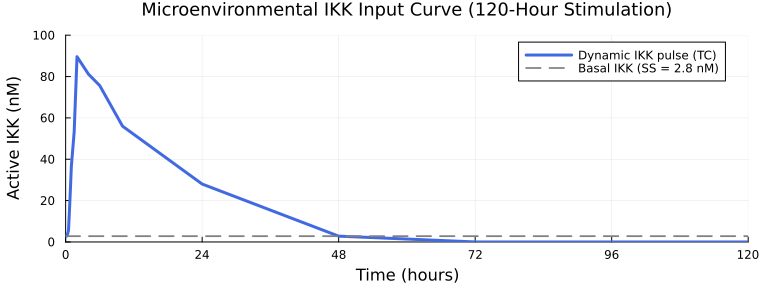

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames
using Random
using Statistics
using Base.Threads

gr()

function build_multiscale_model(base_dir::AbstractString="multiscale")
    modules = ["NFkB", "cellCycle", "apoptosis", "differentiation"]
    mod_dir = joinpath(base_dir, "moduleDefinitionFiles")
    comb_dir = "combinedMultiscale"
    mkpath(comb_dir)

    link_rxn = CSV.read(joinpath(mod_dir, "linking", "reactions.csv"), DataFrame; stringtype=String, types=String)
    link_par = CSV.read(joinpath(mod_dir, "linking", "parameters.csv"), DataFrame; stringtype=String, types=String)
    link_rl  = CSV.read(joinpath(mod_dir, "linking", "rateLaws.csv"), DataFrame; stringtype=String, types=String)
    replace!(link_rxn.Substrate, missing => "")
    replace!(link_rxn.Products,  missing => "")

    link_par[:, 1] = link_par[:, 1] .* "-linking"
    link_rxn.Parameters = [ismissing(p) ? missing : join([x * "-linking" for x in split(p, " ")], " ") for p in link_rxn.Parameters]

    rxn_all = copy(link_rxn)
    par_all = copy(link_par)
    rl_all  = copy(link_rl)

    for m in modules
        r_df = CSV.read(joinpath(mod_dir, m, "reactions.csv"), DataFrame; stringtype=String, types=String)
        p_df = CSV.read(joinpath(mod_dir, m, "parameters.csv"), DataFrame; stringtype=String, types=String)
        l_df = CSV.read(joinpath(mod_dir, m, "rateLaws.csv"), DataFrame; stringtype=String, types=String)
        replace!(r_df.Substrate, missing => "")
        replace!(r_df.Products,  missing => "")

        drop_r = [i for (i, row) in enumerate(eachrow(r_df))
                  if any((link_rxn.Substrate .== row.Substrate) .& (link_rxn.Products .== row.Products))]
        delete!(r_df, drop_r)
        r_df.Parameters = [ismissing(p) ? missing : join([x * "-" * m for x in split(p, " ")], " ") for p in r_df.Parameters]
        append!(rxn_all, r_df)

        drop_p = [i for (i, row) in enumerate(eachrow(p_df))
                  if any(link_par.parameter .== row.parameter) || occursin("p[", row.value)]
        delete!(p_df, drop_p)
        p_df.parameter = p_df.parameter .* ("-" * m)
        append!(par_all, p_df)
        append!(rl_all, l_df)
    end

    CSV.write(joinpath(comb_dir, "reactions.csv"),  rxn_all)
    CSV.write(joinpath(comb_dir, "parameters.csv"), par_all)
    CSV.write(joinpath(comb_dir, "rateLaws.csv"),   rl_all)

    run(`python3 $(joinpath(base_dir, "csv2model-multiscale.py")) $(joinpath(comb_dir, "reactions.csv")) $(joinpath(comb_dir, "parameters.csv")) $(joinpath(comb_dir, "rateLaws.csv")) odeMultiscaleModel.jl param`)
    return comb_dir
end

comb_dir = build_multiscale_model("multiscale")
include("variableNames.jl")
tdfunc = t -> 0.0
include("scanIncludes.jl")
include("multiscale/fixSpecies.jl")

idx(name) = findfirst(==(name), syms)
const idx_Rb      = idx("Rb")
const idx_E2FRb   = idx("E2F_Rb")
const idx_pE2FRb  = idx("pE2F_Rb")
const idx_HypoPRb = idx("HypoP_Rb")
const idx_r31Sw   = idx("r31switch")
const idx_Cdh1    = idx("Cdh1")
const idx_FateSw  = idx("fateSwitch")
const idx_CPARP   = idx("CPARP")
const idx_Mass    = idx("Mass")
const idx_GM      = idx("GM")
const idx_IRF4    = idx("IRF4")
const idx_AID     = idx("AID")
const idx_Blimp1  = idx("Blimp1")
const idx_Pax5    = idx("Pax5")
const idx_Bcl6    = idx("Bcl6")
const idx_Bcl2t   = idx("Bcl2t")
const idx_Ligand  = idx("L")

# Clamp death ligand L in both phases, and Bcl2t + differentiation markers during pre-simulation
fixSpecies("odeMultiscaleModel.jl",   "odeMultiscaleTC.jl", idx_Ligand)
fixSpecies("odeMultiscaleTC.jl",      "odeMultiscaleSS.jl", idx_Bcl2t)
for s_i in (idx_IRF4, idx_AID, idx_Blimp1, idx_Bcl6, idx_Pax5)
    fixSpecies("odeMultiscaleSS.jl",  "odeMultiscaleSS.jl", s_i)
end

# Dynamic IKK input curve (piecewise linear interpolation, as in Tutorial 3)
const totalIKK = 280.0
const basalIKK = totalIKK / 100.0
const IKKParamTime = Float64[0, 15, 30, 45, 60, 90, 120, 240, 360, 600, 1440, 2880, 4320, 5760, 7200, 8640, 14400]
const IKKParamVals = Float64[1, 1, 2, 7, 13, 19, 32, 29, 27, 20, 10, 1, 0, 0, 0, 0, 0] ./ 100.0

function ikkTC(t::Float64)::Float64
    t <= IKKParamTime[1] && return IKKParamVals[1] * totalIKK
    t >= IKKParamTime[end] && return IKKParamVals[end] * totalIKK
    @inbounds for i in 1:(length(IKKParamTime) - 1)
        if t <= IKKParamTime[i + 1]
            frac = (t - IKKParamTime[i]) / (IKKParamTime[i + 1] - IKKParamTime[i])
            return max(IKKParamVals[i] + frac * (IKKParamVals[i + 1] - IKKParamVals[i]), 0.0) * totalIKK
        end
    end
    return 0.0
end
ikkSS(t::Float64)::Float64 = basalIKK

# Specialise the 4 time-dependent parameter entries so `p` is a fast, concrete Vector{Float64}
const td_indices = [i for (i, v) in enumerate(paramVals) if !(v isa Real)]
for (src, dst, fn_name, ikk_name) in [
    ("odeMultiscaleSS.jl", "odeSS_typed.jl", "odeSS_typed!", "ikkSS"),
    ("odeMultiscaleTC.jl", "odeTC_typed.jl", "odeTC_typed!", "ikkTC"),
]
    code_str = read(src, String)
    code_str = replace(code_str, "function odeMultiscaleModel!" => "function $fn_name")
    for ti in td_indices
        code_str = replace(code_str, "p[$ti](t)" => "$(ikk_name)(t)")
    end
    code_str = replace(code_str, r"maximum\(\[([^,\]]+),0\]\)" => s"max(\1, 0.0)")
    write(dst, code_str)
end

include("odeSS_typed.jl")
include("odeTC_typed.jl")

const base_p = Float64[v isa Real ? Float64(v) : 0.0 for v in paramVals]
const idx_NIKdeg = findfirst(==("k1_NIKConstDeg-NFkB"), parameterNameList)

const base_y0 = zeros(Float64, length(syms))
for row in eachrow(CSV.read("multiscale/initialConditions/fullModelInits.csv", DataFrame; header=false))
    i = idx(String(row[1]))
    !isnothing(i) && (base_y0[i] = Float64(row[2]))
end

const p_meta = CSV.read(joinpath(comb_dir, "parameters.csv"), DataFrame;
                        types=Dict(:parameter => String, :value => String, :distribute => Int))
const dist_mask = Bool[p_meta.distribute[findfirst(==(nm), p_meta.parameter)] == 1 for nm in parameterNameList]

println("Multiscale model ready: ", length(syms), " species, ", length(base_p),
        " parameters (", count(dist_mask), " heterogeneous), ", nthreads(), " CPU thread(s).")

# Visualise the dynamic IKK activation pulse (0 to 120 hours)
t_grid = collect(0.0:10.0:7200.0)
p_ikk = plot(t_grid ./ 60.0, ikkTC.(t_grid), lw=3, color=:royalblue, label="Dynamic IKK pulse (TC)")
hline!(p_ikk, [basalIKK], linestyle=:dash, color=:gray, lw=1.8, label="Basal IKK (SS = $(round(basalIKK, digits=1)) nM)")
plot!(p_ikk, xlabel="Time (hours)", ylabel="Active IKK (nM)",
      title="Microenvironmental IKK Input Curve (120-Hour Stimulation)", titlefontsize=12,
      xlims=(0, 120), xticks=0:24:120, ylims=(0, 100), size=(760, 300))
p_ikk

---

## Step 2: Define the Callbacks & Full-Trajectory Single-Cell Lineage Runner

Now let's define the callbacks and a `simulate_lineage_trace(mods)` function that runs **one founder cell** through its full life — saving every generation's molecular time courses (`Mass`, `cMyc`, `Bcl2t`, `RelAnp50n`, `cRelnp50n`, `CPARP`) along with its exact division and death timestamps.

In [2]:
# 1. RB restriction-point switch
function cond_rb(u, t, integrator)
    num = u[idx_Rb] + u[idx_E2FRb] + u[idx_pE2FRb]
    den = num + u[idx_HypoPRb]
    return (num / max(den, 1e-12)) - 0.8
end
aff_rb_pos!(integ) = (integ.u[idx_r31Sw] = 0.0)
aff_rb_neg!(integ) = (integ.u[idx_r31Sw] = 1.0)

# 2. Mitotic division callback (time course): sets fateSwitch = 1 and stops mother cell
cond_cdh(u, t, integrator) = u[idx_Cdh1] - 0.2
function aff_cdh_div!(integ)
    if integ.u[idx_Mass] >= 1.0
        integ.uprev[idx_FateSw] = 1.0
        integ.u[idx_FateSw]     = 1.0
        terminate!(integ)
    end
end

# 3. Apoptosis death callback: sets fateSwitch = 2 when Cleaved PARP crosses 2500
cond_cparp(u, t, integrator) = u[idx_CPARP] - 2500.0
function aff_cparp!(integ)
    integ.uprev[idx_FateSw] = 2.0
    integ.u[idx_FateSw]     = 2.0
    terminate!(integ)
end

# 4. Pre-simulation division callback: halves Mass/GM in place without spawning daughters
function aff_cdh_ss!(integ)
    integ.u[idx_Mass] *= 0.5
    integ.u[idx_GM]   *= 0.5
    integ.u[idx_r31Sw] = 1.0
    integ.u[idx_Bcl2t] = 277.0
    integ.u[idx_Cdh1]  = 1.0
end

const cb_rb     = ContinuousCallback(cond_rb, aff_rb_pos!, aff_rb_neg!)
const cb_div    = ContinuousCallback(cond_cdh, aff_cdh_div!, nothing)
const cb_death  = ContinuousCallback(cond_cparp, aff_cparp!, nothing)
const cb_ss_div = ContinuousCallback(cond_cdh, aff_cdh_ss!, nothing)

const cbs_tc    = CallbackSet(cb_rb, cb_div, cb_death)
const cbs_nodiv = CallbackSet(cb_rb, cb_death)
const cbs_ss    = CallbackSet(cb_rb, cb_ss_div)

const f_ss   = ODEFunction(odeSS_typed!)
const f_tc   = ODEFunction(odeTC_typed!)
const ms_alg = Rodas5P(autodiff=AutoFiniteDiff())

const idx_cMyc     = idx("cMyc")
const idx_RelAp50n = idx("RelAnp50n")
const idx_cRelp50n = idx("cRelnp50n")

function simulate_lineage_trace(mods::Dict{String, Float64}=Dict{String, Float64}();
                                maxGens::Int=8, maxTimeTC::Float64=7200.0, preSimTime::Float64=1440.0)
    p = copy(base_p)
    for (k, v) in mods
        i = findfirst(==(k), parameterNameList)
        isnothing(i) && error("Parameter '$k' not found in parameterNameList")
        p[i] *= v
    end

    # Phase 1: 24-hour resting steady state
    y0 = copy(base_y0)
    y0[idx_Bcl2t]  = 277.0
    y0[idx_Ligand] = 0.0
    sol_ss = solve(ODEProblem(f_ss, y0, (0.0, preSimTime), p), ms_alg;
                   callback=cbs_ss, abstol=1e-5, reltol=1e-3, save_everystep=false)

    u_cur = copy(sol_ss.u[end])
    u_cur[idx_Cdh1]   = 1.0
    u_cur[idx_IRF4]   = 0.0
    u_cur[idx_AID]    = 0.0
    u_cur[idx_Blimp1] = 0.0
    u_cur[idx_Pax5]   = 1.0
    u_cur[idx_Bcl6]   = 0.0
    u_cur[idx_Ligand] = 1.0
    p[idx_NIKdeg]    /= 10.0

    # Phase 2: step through generations until apoptosis (fate = 2) or 120 h
    t_all     = Float64[]
    mass_all  = Float64[]
    cparp_all = Float64[]
    bcl2t_all = Float64[]
    cmyc_all  = Float64[]
    div_hours = Float64[]
    fate_hours = Float64[]

    t_birth = 1.0
    final_fate = 0
    for gen in 1:maxGens
        cb = gen < maxGens ? cbs_tc : cbs_nodiv
        sol = solve(ODEProblem(f_tc, u_cur, (t_birth, maxTimeTC), p), ms_alg;
                    callback=cb, abstol=1e-5, reltol=1e-3, saveat=15.0)
        append!(t_all,     sol.t ./ 60.0)
        append!(mass_all,  [u[idx_Mass]  for u in sol.u])
        append!(cparp_all, [u[idx_CPARP] for u in sol.u])
        append!(bcl2t_all, [u[idx_Bcl2t] for u in sol.u])
        append!(cmyc_all,  [u[idx_cMyc]  for u in sol.u])

        t_end = sol.t[end]
        push!(fate_hours, t_end / 60.0)
        fate = gen < maxGens ? round(Int, sol.u[end][idx_FateSw]) : 2
        final_fate = fate

        if fate == 1 && t_end < maxTimeTC - 1e-6
            push!(div_hours, t_end / 60.0)
            u_next = copy(sol.u[end])
            u_next[u_next .< 1e-12] .= 0.0
            u_next[idx_Mass]  *= 0.5
            u_next[idx_r31Sw]  = 1.0
            u_next[idx_FateSw] = 0.0
            u_next[idx_CPARP]  = 0.0
            u_next[idx_Cdh1]   = 1.0
            u_cur   = u_next
            t_birth = t_end
        else
            break
        end
    end

    return (
        t_hours    = t_all,
        mass       = mass_all,
        cparp      = cparp_all,
        bcl2t      = bcl2t_all,
        cmyc       = cmyc_all,
        div_hours  = div_hours,
        fate_hours = fate_hours,
        generations = length(fate_hours),
        peak_cells = 2^(length(fate_hours) - 1),
        death_hour = fate_hours[end],
        final_fate = final_fate,
    )
end

println("Single-cell lineage tracer simulate_lineage_trace(mods) ready.")

Single-cell lineage tracer simulate_lineage_trace(mods) ready.


---

## Step 3: Watch One Cell Grow, Divide Repeatedly, and Die!

Let's simulate a single founder cell under two conditions — **Wild-Type (`WT`)** and **`BCL2 × 5`** — and watch:
1. **Top panel (`Mass`):** Smooth cell growth followed by a sharp vertical drop (halving by `0.5×`) every time the **division callback** fires.
2. **Middle panel (`Cleaved PARP`):** Stays near zero while `Bcl2t` protects the mitochondria, then spikes steeply across `2500` when the **apoptosis callback** fires and ends the lineage.
3. **Bottom panel (Branching Lineage Tree):** How each division doubles the number of live cells (`1 → 2 → 4 → 8`), until Cleaved PARP kills the entire branch (`×`).

WT single cell:      divided 1 time(s) at 

[24.0] h -> died at 26.3 h (peak = 2 cells)
BCL2 × 5 single cell: divided 3 time(s) at [24.0, 35.6, 46.0] h -> died at 52.6 h (peak = 8 cells)


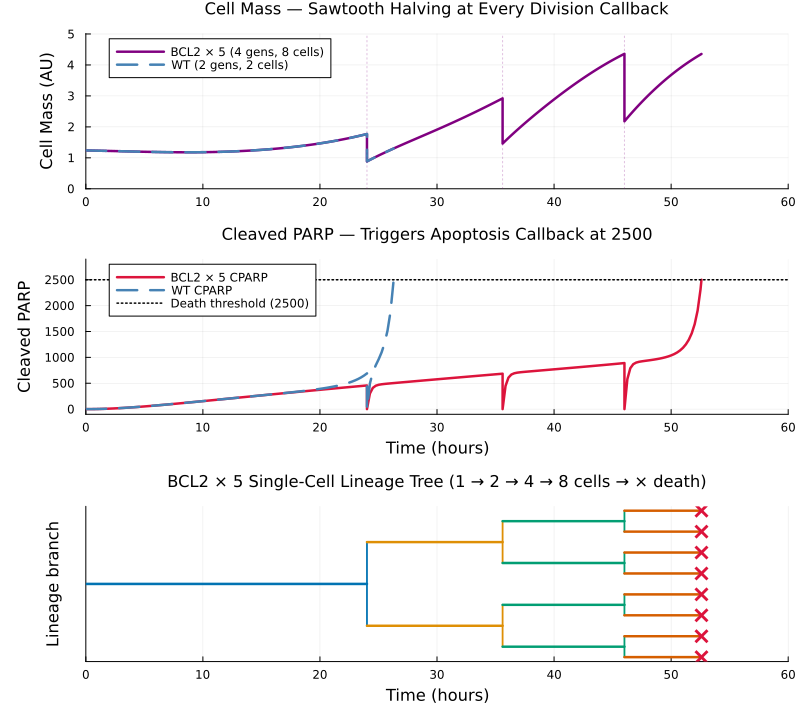

In [3]:
tr_wt   = simulate_lineage_trace(Dict{String, Float64}())
tr_bcl2 = simulate_lineage_trace(Dict("k1_bcl2Exp-linking" => 5.0))

println("WT single cell:      divided ", length(tr_wt.div_hours),   " time(s) at ", round.(tr_wt.div_hours, digits=1),   " h -> died at ", round(tr_wt.death_hour, digits=1),   " h (peak = ", tr_wt.peak_cells,   " cells)")
println("BCL2 × 5 single cell: divided ", length(tr_bcl2.div_hours), " time(s) at ", round.(tr_bcl2.div_hours, digits=1), " h -> died at ", round(tr_bcl2.death_hour, digits=1), " h (peak = ", tr_bcl2.peak_cells, " cells)")

# Helper to draw a clean binary lineage tree for a single founder cell
function plot_single_tree(fate_hours::Vector{Float64}, title_str::String; xlim_h::Float64=65.0)
    n_gen = length(fate_hours)
    pal = palette(:seaborn_colorblind)
    p = plot(title=title_str, titlefontsize=11, xlabel="Time (hours)", ylabel="Lineage branch",
             xlims=(0, xlim_h), yticks=false, legend=false, grid=true)
    ys = [0.0]
    t_prev = 0.0
    span = 2.0^(n_gen - 1)
    for g in 1:n_gen
        t_cur = fate_hours[g]
        col = pal[mod1(g, length(pal))]
        next_ys = Float64[]
        step = span / (2.0^g)
        for y in ys
            plot!(p, [t_prev, t_cur], [y, y], lw=2.5, color=col)
            if g < n_gen
                plot!(p, [t_cur, t_cur], [y - step, y + step], lw=1.8, color=col)
                push!(next_ys, y - step, y + step)
            else
                scatter!(p, [t_cur], [y], marker=:xcross, ms=6, msw=2, color=:crimson)
            end
        end
        ys = next_ys
        t_prev = t_cur
    end
    return p
end

p1 = plot(tr_bcl2.t_hours, tr_bcl2.mass, lw=2.5, color=:purple, label="BCL2 × 5 (4 gens, 8 cells)")
plot!(p1, tr_wt.t_hours, tr_wt.mass, lw=2.5, color=:steelblue, linestyle=:dash, label="WT (2 gens, 2 cells)")
vline!(p1, tr_bcl2.div_hours, color=:purple, alpha=0.25, linestyle=:dot, label=false)
plot!(p1, ylabel="Cell Mass (AU)", title="Cell Mass — Sawtooth Halving at Every Division Callback",
      titlefontsize=11, xlims=(0, 60), ylims=(0, maximum(tr_bcl2.mass) * 1.15), legend=:topleft)

p2 = plot(tr_bcl2.t_hours, tr_bcl2.cparp, lw=2.5, color=:crimson, label="BCL2 × 5 CPARP")
plot!(p2, tr_wt.t_hours, tr_wt.cparp, lw=2.5, color=:steelblue, linestyle=:dash, label="WT CPARP")
hline!(p2, [2500.0], color=:black, linestyle=:dot, lw=1.5, label="Death threshold (2500)")
plot!(p2, xlabel="Time (hours)", ylabel="Cleaved PARP",
      title="Cleaved PARP — Triggers Apoptosis Callback at 2500",
      titlefontsize=11, xlims=(0, 60), ylims=(-100, 2900), legend=:topleft)

p3 = plot_single_tree(tr_bcl2.fate_hours, "BCL2 × 5 Single-Cell Lineage Tree (1 → 2 → 4 → 8 cells → × death)"; xlim_h=60.0)

plot(p1, p2, p3, layout=(3, 1), size=(800, 720), left_margin=4Plots.mm)

Look at what the callbacks just did automatically:
- In **WT**, the founder cell divides once at **24.0 h** (producing 2 Generation-2 daughters), and those daughters cross the `CPARP = 2500` apoptosis threshold at **26.3 h**.
- In **`BCL2 × 5`**, elevated `Bcl2t` holds `CPARP` near zero twice as long (until **52.6 h**), allowing the cell to complete **three divisions** (`24.0 h`, `35.6 h`, `46.0 h`) and reach **8 cells** before dying!

---

## Interactive Exercise: Watch Single-Cell Double-Hit Synergy Emerge!

Before we scale up to a heterogeneous population in Chapter 2, let's test **MYC × 5** (`"k1_mycExp-linking" => 5.0`), **BCL2 × 5** (`"k1_bcl2Exp-linking" => 5.0`), and **MYC + BCL2 × 5** (both together!) in a single founder cell.

**Your task:** Edit `my_mods` below to test `MYC × 5` alone, then `MYC + BCL2 × 5` together, and compare `Peak_Cells` against the WT (`2` cells) and `BCL2 × 5` (`8` cells) baselines!

Row,Condition,Divisions,Generations,Peak_Cells,Death_Hour
,String,Int64,Int64,Int64,Float64
1,WT,1,2,2,26.3
2,BCL2 × 5,3,4,8,52.6
3,My Perturbation,1,2,2,26.3


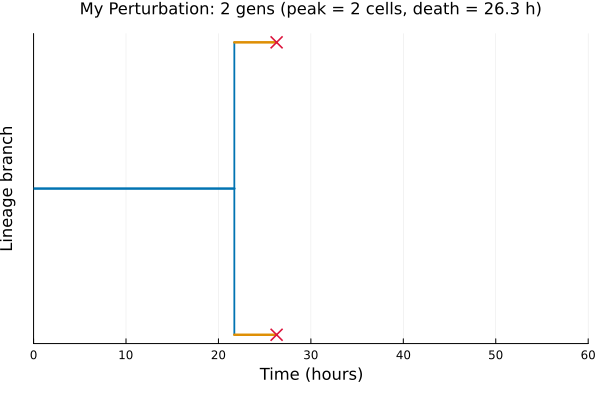

In [4]:
# Exercise: Test MYC x 5 alone, then MYC + BCL2 x 5 together!
my_label = "My Perturbation"
my_mods  = Dict("k1_mycExp-linking" => 5.0)   # <-- Try adding "k1_bcl2Exp-linking" => 5.0 !

tr_my = simulate_lineage_trace(my_mods)

display(DataFrame(
    Condition   = ["WT", "BCL2 × 5", my_label],
    Divisions   = [length(tr_wt.div_hours), length(tr_bcl2.div_hours), length(tr_my.div_hours)],
    Generations = [tr_wt.generations, tr_bcl2.generations, tr_my.generations],
    Peak_Cells  = [tr_wt.peak_cells, tr_bcl2.peak_cells, tr_my.peak_cells],
    Death_Hour  = round.([tr_wt.death_hour, tr_bcl2.death_hour, tr_my.death_hour], digits=1),
))

plot_single_tree(tr_my.fate_hours, "$(my_label): $(tr_my.generations) gens (peak = $(tr_my.peak_cells) cells, death = $(round(tr_my.death_hour, digits=1)) h)"; xlim_h=60.0)

````{admonition} Hint
:class: dropdown tip

Set:
```julia
my_label = "MYC + BCL2 × 5"
my_mods  = Dict("k1_mycExp-linking" => 5.0, "k1_bcl2Exp-linking" => 5.0)
```
and compare how many divisions fit inside the 52.6-hour survival window!
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
combos = [
    ("WT",              Dict{String, Float64}()),
    ("MYC × 5",         Dict("k1_mycExp-linking" => 5.0)),
    ("BCL2 × 5",        Dict("k1_bcl2Exp-linking" => 5.0)),
    ("MYC + BCL2 × 5",  Dict("k1_mycExp-linking" => 5.0, "k1_bcl2Exp-linking" => 5.0)),
    ("BCL6 × 5",        Dict("k1_s_Bcl6-differentiation" => 5.0)),
    ("MYC + BCL6 × 5",  Dict("k1_mycExp-linking" => 5.0, "k1_s_Bcl6-differentiation" => 5.0)),
]

rows = [(nm, simulate_lineage_trace(m)) for (nm, m) in combos]
display(DataFrame(
    Condition   = [r[1] for r in rows],
    Divisions   = [length(r[2].div_hours) for r in rows],
    Peak_Cells  = [r[2].peak_cells for r in rows],
    Death_Hour  = [round(r[2].death_hour, digits=1) for r in rows],
))
```

Look at the mechanism of **Double-Hit synergy** already visible in a single cell:
- `MYC × 5` alone divides 2.3 h earlier (`21.7 h` vs `24.0 h`), but still dies at `26.3 h` → **`2` cells** (`+0` over WT).
- `BCL2 × 5` alone extends survival to `52.6 h`, fitting 3 divisions → **`8` cells** (`+6` over WT).
- Together, **`MYC + BCL2 × 5`** combines faster G1 progression (`21.7, 31.1, 40.2, 49.7 h`) with `52.6 h` survival — squeezing in a **4th division** and doubling peak output to **`16` cells** (far above the additive expectation of `8` cells)!
````

Now move on to **[2. Heterogeneous Populations & MYC + BCL2 Synergy (Norris *et al.* Figure 2B)](./02-double-hit-myc-bcl2-figure2.ipynb)** to scale this up to a population of heterogeneous lymphoma cells!